In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from xgboost import XGBRegressor

In [4]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
y = housing.target

In [5]:
# ==========================================
# Завдання 1. Дерево рішень
# ==========================================
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms"]
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
r2_dt = r2_score(y_test, y_pred_dt)

print(f"Завдання 1 — R² (DecisionTreeRegressor): {r2_dt:.4f}")

Завдання 1 — R² (DecisionTreeRegressor): 0.5075


In [6]:
# ==========================================
# Завдання 2. Порівняння одного дерева й ансамблю дерев
# ==========================================
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)

print("\nЗавдання 2 — Порівняння моделей:")
print("| Модель | R² на тестовій вибірці |")
print("| :--- | :--- |")
print(f"| DecisionTreeRegressor (max_depth=4) | {r2_dt:.4f} |")
print(f"| RandomForestRegressor (n_estimators=100) | {r2_rf:.4f} |")


Завдання 2 — Порівняння моделей:
| Модель | R² на тестовій вибірці |
| :--- | :--- |
| DecisionTreeRegressor (max_depth=4) | 0.5075 |
| RandomForestRegressor (n_estimators=100) | 0.5879 |


In [7]:
# ==========================================
# Завдання 3. Градієнтний бустинг (XGBRegressor)
# ==========================================
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"\nЗавдання 3 — R² (XGBRegressor): {r2_xgb:.4f}")
print(f"Різниця з RandomForestRegressor: {r2_xgb - r2_rf:+.4f}")


Завдання 3 — R² (XGBRegressor): 0.5993
Різниця з RandomForestRegressor: +0.0114


c:\Users\Elizaveta\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Завдання 4 — Результати класифікації:
Confusion Matrix:
[[1721  356]
 [ 357 1694]]
Accuracy:  0.8273
Precision: 0.8263
Recall:    0.8259
F1-score:  0.8261


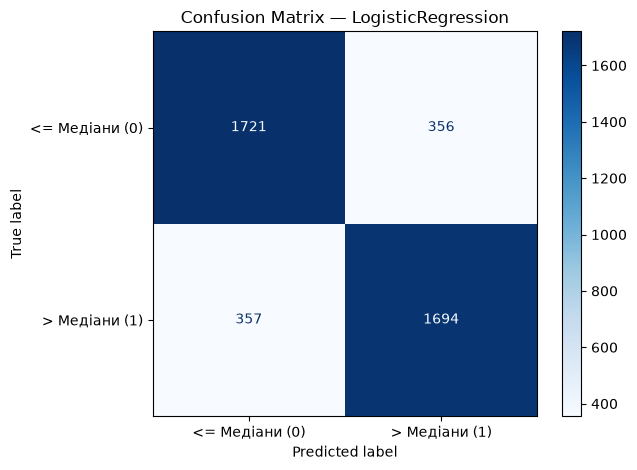

In [8]:
# ==========================================
# Завдання 4. Задача класифікації (LogisticRegression)
# ==========================================
X_full = housing.data
median_price = np.median(y)
y_class = (y > median_price).astype(int)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_full, y_class, test_size=0.2, random_state=42
)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_cls, y_train_cls)
y_pred_cls = log_reg.predict(X_test_cls)

cm = confusion_matrix(y_test_cls, y_pred_cls)
acc = accuracy_score(y_test_cls, y_pred_cls)
prec = precision_score(y_test_cls, y_pred_cls)
rec = recall_score(y_test_cls, y_pred_cls)
f1 = f1_score(y_test_cls, y_pred_cls)

print("\nЗавдання 4 — Результати класифікації:")
print("Confusion Matrix:")
print(cm)
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<= Медіани (0)", "> Медіани (1)"],
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — LogisticRegression")
plt.tight_layout()
plt.show()